# Классификация категории товара по названию

**Соревнование:** [MEPhI: NLP: Classification: Subject Detection](https://www.kaggle.com/competitions/mephi-product-title-subject-detection)  
**Метрики:** F1-macro (`sklearn`, `zero_division=0`)  
**ФИО / группа:** _Волконская Анастасия А, М25-555_


Данные: `train.csv` / `test.csv` .
❗до запуска ноутбука проверить наличие данных в Content для возможности autorun всех ячеек без ошибок и ручной загрузки.

Внешняя разметка теста и prod-классификатор Naitii не используются.


In [30]:
# @title Установка зависимостей
import importlib
import subprocess
import sys

for pkg, mod in (
    ("pandas", "pandas"),
    ("numpy", "numpy"),
    ("scikit-learn", "sklearn"),
    ("matplotlib", "matplotlib"),
):
    try:
        importlib.import_module(mod)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])
print("зависимости OK")

зависимости OK


In [31]:
# @title §1. Импорты и константы
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import time
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
_WS = re.compile(r"\s+")


def output_dir() -> Path:
    for p in (Path("/kaggle/working"), Path("/content")):
        if p.exists():
            return p
    return Path(".")


OUT_DIR = output_dir()
BASELINE_PATH = OUT_DIR / "baseline_submission.csv"
SUBMIT_PATH = OUT_DIR / "submission.csv"
print("OUT_DIR =", OUT_DIR.resolve())

OUT_DIR = /kaggle/working


In [32]:
# @title §2. Загрузка данных
_WS = re.compile(r"\s+")

def find_csv(name: str) -> Path:
    explicit = [
        Path("/kaggle/input/mephi-product-title-subject-detection") / name,
        Path("/content/data") / name,
        Path("/content") / name,
        Path("data") / name,
        Path("../data") / name,
        Path(name),
    ]
    kaggle_root = Path("/kaggle/input")
    if kaggle_root.exists():
        explicit.extend(sorted(kaggle_root.glob(f"**/{name}")))
    for path in explicit:
        if path.is_file():
            return path
    raise FileNotFoundError(
        f"{name} не найден. Положите файл в /content/data/ (Colab) "
        "или подключите данные соревнования (Kaggle)."
    )


def normalize_text(text) -> str:
    if not isinstance(text, str):
        text = "" if text is None or (isinstance(text, float) and np.isnan(text)) else str(text)
    return _WS.sub(" ", text.strip().lower().replace("ё", "е"))


train_path = find_csv("train.csv")
test_path = find_csv("test.csv")
train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

need_train, need_test = {"id", "text", "subject"}, {"id", "text"}
if not need_train.issubset(train.columns):
    raise ValueError(f"train.csv колонки {list(train.columns)}")
if not need_test.issubset(test.columns):
    raise ValueError(f"test.csv колонки {list(test.columns)}")

train = train.copy()
test = test.copy()
train["text_norm"] = train["text"].map(normalize_text)
test["text_norm"] = test["text"].map(normalize_text)

overlap_raw = set(train["text"]) & set(test["text"])
print("train", train_path)
print("test ", test_path)
print("строк train/test:", len(train), len(test), "| классов:", train["subject"].nunique())
print("пересечение raw text train∩test:", len(overlap_raw))
if overlap_raw:
    raise ValueError(f"утечка raw text: {len(overlap_raw)}")

train /kaggle/input/competitions/mephi-product-title-subject-detection/train.csv
test  /kaggle/input/competitions/mephi-product-title-subject-detection/test.csv
строк train/test: 31670 2046 | классов: 341
пересечение raw text train∩test: 0


**Вывод: загрузка.** Данные читаются из `train.csv` / `test.csv` . Пересечения сырых названий train∩test нет (проверено, сколько названий из поля text (как в файле, без изменения регистра и буквы «ё») встречаются и в обучении, и в тесте, пересечение raw text train∩test: 0). Ноль означает, что ни одно название товара из обучения в точности не совпало с названием из теста.

Далее — EDA и две модели (baseline и финал).


=== пропуски (NaN) ===
           train  test
id             0   0.0
subject        0   NaN
text           0   0.0
text_norm      0   0.0

=== пустые названия (после str) ===
  train: 0 | test: 0

=== структура train ===
  классов: 341
  строк: 31670 | unique text_norm: 8095
  дубликатов text_norm (лишние строки): 23575
  singleton-классов (1 строка в train): 140
  длина text (символы): median 16.0 | p95 45.0 | p99 61.0 | max 106
  интерпретация длины: экстремально длинные названия не отрезаем — они несут сигнал; отдельной обрезки «выбросов» нет.

=== признаки для моделирования ===
  id — идентификатор, в обучение и TF-IDF не входит.
  subject — целевая метка (только train).
  text → text_norm — единственный вход модели (нормализация в §2).
  корреляционная матрица числовых признаков не строится: нет табличных фич, кроме текста.


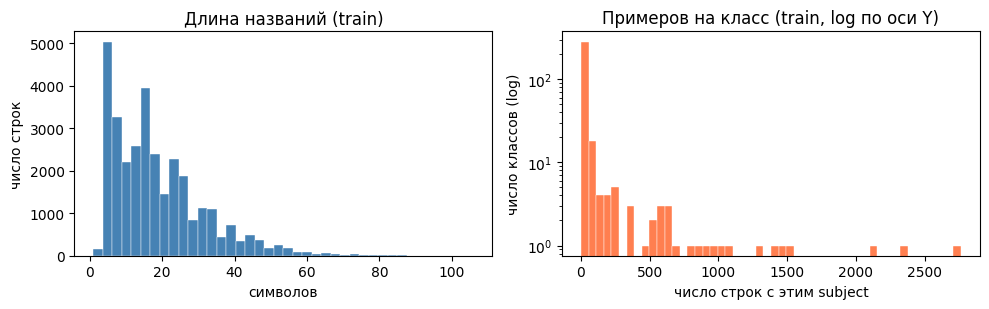


топ-5 классов по частоте:
subject
кроссовки    2764
туфли        2364
ботинки      2153
платья       1526
кольца       1454


In [33]:
# @title §3. EDA: качество данных, распределения, визуализации
print("=== пропуски (NaN) ===")
miss = pd.DataFrame({"train": train.isna().sum(), "test": test.isna().sum()})
print(miss.to_string())
if miss.to_numpy().max() > 0:
    print("  → числовые NaN: заполнение не требуется, см. normalize_text для не-строк.")

text_tr = train["text"].astype(str)
text_te = test["text"].astype(str)
empty_tr = int((text_tr.str.strip() == "").sum())
empty_te = int((text_te.str.strip() == "").sum())
print("\n=== пустые названия (после str) ===")
print("  train:", empty_tr, "| test:", empty_te)
if empty_tr or empty_te:
    print("  → пустые строки попадут в text_norm как ''; в модели остаются как есть.")

n_classes = int(train["subject"].nunique())
vc = train["subject"].value_counts()
text_lens = text_tr.str.len()
print("\n=== структура train ===")
print("  классов:", n_classes)
print("  строк:", len(train), "| unique text_norm:", train["text_norm"].nunique())
print("  дубликатов text_norm (лишние строки):", len(train) - train["text_norm"].nunique())
print("  singleton-классов (1 строка в train):", int((vc == 1).sum()))
print(
    "  длина text (символы): median",
    float(text_lens.median()),
    "| p95",
    float(text_lens.quantile(0.95)),
    "| p99",
    float(text_lens.quantile(0.99)),
    "| max",
    int(text_lens.max()),
)
print(
    "  интерпретация длины: экстремально длинные названия не отрезаем — они несут сигнал; "
    "отдельной обрезки «выбросов» нет."
)

print("\n=== признаки для моделирования ===")
print("  id — идентификатор, в обучение и TF-IDF не входит.")
print("  subject — целевая метка (только train).")
print("  text → text_norm — единственный вход модели (нормализация в §2).")
print("  корреляционная матрица числовых признаков не строится: нет табличных фич, кроме текста.")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(text_lens, bins=40, color="steelblue", edgecolor="white", linewidth=0.3)
axes[0].set_title("Длина названий (train)")
axes[0].set_xlabel("символов")
axes[0].set_ylabel("число строк")

per_class = vc.to_numpy()
axes[1].hist(per_class, bins=50, color="coral", edgecolor="white", linewidth=0.3)
axes[1].set_yscale("log")
axes[1].set_title("Примеров на класс (train, log по оси Y)")
axes[1].set_xlabel("число строк с этим subject")
axes[1].set_ylabel("число классов (log)")

plt.tight_layout()
try:
    get_ipython()
    plt.show()
except NameError:
    plt.close()

print("\nтоп-5 классов по частоте:")
print(vc.head(5).to_string())


**Вывод: EDA (для моделей).**

341 класс, 8095 уникальных text_norm при 31670 строках train — сильные дубликаты названий.

В датасете много классов (~340+), длинный хвост (десятки классов с 1 примером), названия короткие. Для F1-macro важны редкие классы; дубликаты названий в train лучше не раздувать — финальная модель учится на **уникальных** `text_norm`.

- **Пропуски и пустые значения** проверены явно (`isna`, пустой `text`); для не-строк используется нормализация в §2. Отдельного imputation нет — признаков с массовыми NaN нет.
- **Выбросы:** для текста смотрим хвост **длины** (p95/p99); агрессивная обрезка не применяется — длинные названия остаются в обучении.
- **Нерелевантные поля:** `id` не используется как признак; таргет `subject` не подаётся в векторизатор. В модель идёт только **`text_norm`**.
- **Корреляции** в классическом смысле не считаются (одномодальная NLP-задача); вместо этого — **дисбаланс классов** (гистограмма «примеров на класс», log-шкала) и **дубликаты** названий → решение обучаться на **уникальных** `text_norm`.
- **Feature engineering:** нормализация текста, TF-IDF (word + char);
- выводы EDA объясняют выбор `FIT`, `class_weight='balanced'` и риск macro-F1 на редких классах.


In [34]:
# @title §4. Общие функции
def unique_text_frame(df: pd.DataFrame) -> pd.DataFrame:
    return df.drop_duplicates(subset=["text_norm"], keep="first")


def validate_submission(submission: pd.DataFrame, test_df: pd.DataFrame, labels: set) -> None:
    if list(submission.columns) != ["id", "subject"]:
        raise ValueError(f"колонки {list(submission.columns)}")
    if len(submission) != len(test_df) or set(submission["id"]) != set(test_df["id"]):
        raise ValueError("id не совпадают с test")
    extra = set(submission["subject"]) - labels
    if extra:
        raise ValueError(f"метки вне train: {list(extra)[:5]}")


LABELS = set(train["subject"].unique())
FIT = unique_text_frame(train)
print("строк для обучения (unique text):", len(FIT), "из", len(train))

строк для обучения (unique text): 8095 из 31670


**Вывод: подготовка к обучению моделей.**

- В ячейке из полного train (31670 строк) собрана таблица FIT: для каждого уникального нормализованного названия оставлена одна строка (drop_duplicates по text_norm, первая запись).

- Print: 8095 из 31670. Сам train.csv не менялся. Дальше планируется обучение на таблице FIT, а предсказания — по всем строкам test.

- Baseline. Планируется обучить простую модель: по названию товара будут подсчитываться частоты кусков текста (слова целиком длиной 1–2 и цепочки символов длиной 3–5), затем запустим линейную логистическую регрессию с равным вниманием к редким и частым категориям. Она предскажет категорию для всех строк теста и запишет файл baseline_submission.csv , в соответствии с правилами сдачи. Baseline_submission.csv не является финальным решением и не идёт на лидерборд.

In [35]:
# @title §5. Обучение Baseline → скачивание baseline_submission.csv


def make_tfidf(word_n, char_n, max_w, max_c, min_df) -> ColumnTransformer:
    return ColumnTransformer(
        [
            (
                "word",
                TfidfVectorizer(
                    analyzer="word",
                    ngram_range=word_n,
                    min_df=min_df,
                    max_df=0.98,
                    max_features=max_w,
                    sublinear_tf=True,
                ),
                "text_norm",
            ),
            (
                "char",
                TfidfVectorizer(
                    analyzer="char_wb",
                    ngram_range=char_n,
                    min_df=min_df,
                    max_df=0.98,
                    max_features=max_c,
                    sublinear_tf=True,
                ),
                "text_norm",
            ),
        ],
        sparse_threshold=0.3,
    )


baseline = Pipeline(
    [
        ("features", make_tfidf((1, 2), (3, 5), 80_000, 80_000, 2)),
        (
            "clf",
            LogisticRegression(
                C=2.0,
                max_iter=300,
                class_weight="balanced",
                solver="lbfgs",
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)
baseline.fit(FIT[["text_norm"]], FIT["subject"].to_numpy())
pred_fit = baseline.predict(FIT[["text_norm"]])
print(
    "macro-F1 на FIT:",
    round(f1_score(FIT["subject"], pred_fit, average="macro", zero_division=0), 5),
)
base_pred = baseline.predict(test[["text_norm"]])
print("уникальных subject в pred на test:", int(pd.Series(base_pred).nunique()))
baseline_sub = pd.DataFrame({"id": test["id"], "subject": base_pred})
validate_submission(baseline_sub, test, LABELS)
baseline_sub.to_csv(BASELINE_PATH, index=False)
print("записан", BASELINE_PATH, "строк", len(baseline_sub))


macro-F1 на FIT: 0.92927
уникальных subject в pred на test: 201
записан /kaggle/working/baseline_submission.csv строк 2046


**Вывод:**

- В тесте 2046 товаров. Файл submission должен содержать ровно столько же строк: id + предсказанная категория. По итогам запуска ячейки точное совпадение по числу строк подтверждено.

- Первые результаты обучения на  macro-F1 на FIT = 0.92927. Этот показатель достаточно высокий, но есть риск, что модель угадывает правильные ответы при повторном прогоне на той же выборке.

- уникальных subject в pred на test: 201
Этот показатель требует внимания:
в обучающем датасете 341 категория, на тесте модель назвала только 201 разных классов.
Остальные 140 категорий она ни разу не проставила ни одному тестовому товару. Вероятнее всего всего это редкочастотные классы (у многих в train был 1 пример): линейная модель их почти не выбирает.
По этим классам на тесте F1 будет 0.

### Для example submit сохраним полученный результат, и продумаем пути повышения качества обучения.



**Переход к следующей модели (финал).**

| Наблюдение baseline | Решение |
|---------------------|---------|
| Короткий текст (медиана 16), мало редких классов в pred | Расширить char n-grams (2–6), `min_df=1` |
| Высокий F1 на FIT, но слабее на LB | Заменить LogisticRegression на **LinearSVC** (C=3) на том же `FIT` |
| Дубликаты названий | Оставить обучение на **8095** unique `text_norm` |

Следующая ячейка: TF-IDF (word 1–2, char 2–6) + **LinearSVC**, выход **`submission.csv`**. Ожидаем рост покрытия классов на тесте относительно 201 и сохранение высокого уровня точности предсказания модели.

- TF-IDF даёт очень широкую и «пустую» матрицу: в каждой строке почти все нули и лишь немного ненулевых признаков. Для таких данных обычно достаточно прямого линейного правила: «если в названии встречаются такие-то слова и обрывки букв — скорее этот класс». Нелинейные ядра (например, RBF) на таких размерностях тяжелее по памяти и времени, а выигрыш на коротких названиях небольшой. Поэтому для итоговой модели разумно попробовать LinearSVC с линейным ядром: та же идея, что у baseline, но другой способ провести границу между классами, потому что при том же векторе она оптимизирует зазор между классами и на пограничных, лексически похожих примерах ожидается лучший macro-F1.
- Мы оставляем разреженные TF-IDF-признаки и линейный классификатор как основу для коротких русских названий и 341 класса.
- Линейное ядро выбрано из-за размерности и разреженности. Параметр C=3 подобран сильнее baseline (2.0), чтобы лучше использовать редкие n-граммы при обучении на уникальных текстах.
Про C=3 вместо 2.0
В финальной векторизации планируется не отбрасывать признаки, которые встретились всего один раз (min_df=1), и учиться на уникальных названиях, без повторов одной и той же строки. Ожидание: появится больше редких, но полезных n-грамм. Если взять тот же C, что у baseline (2.0), модель может слишком их приглушить. Гипотеза: чуть более высокий C (=3) даст границе возможность опереться на эти редкие маркеры, не сильно переобучаясь, потому что дубликаты названий в обучении не размножаются.
- Окончательное значение `C` нужно проверить по кросс-валидации или сравнению с baseline на сабмите.

In [36]:
# @title §6. Итоговая модель → итоговый файл для загрузки submission.csv

DO_CV_FOLDS = 3  # 0 — пропустить CV (быстрый прогон)

FINAL_CFG = {
    "word_ngram": (1, 2),
    "char_ngram": (2, 6),
    "max_features_word": 120_000,
    "max_features_char": 150_000,
    "min_df": 1,
    "C": 3.0,
}

print("= §6. Финальная модель: конфиг =")
print("  векторизация: word", FINAL_CFG["word_ngram"], "char_wb", FINAL_CFG["char_ngram"])
print("  max_features:", FINAL_CFG["max_features_word"], "/", FINAL_CFG["max_features_char"])
print("  min_df:", FINAL_CFG["min_df"], "| C:", FINAL_CFG["C"])
print("  clf: LinearSVC, class_weight=balanced, dual=auto, max_iter=4000")
print("  train: FIT (unique text_norm):", len(FIT), "строк,", FIT["subject"].nunique(), "классов")
subj_fit = FIT["subject"].value_counts()
print(
    "  примеров на класс (FIT): min",
    int(subj_fit.min()),
    "median",
    int(subj_fit.median()),
    "max",
    int(subj_fit.max()),
)

final_model = Pipeline(
    [
        (
            "features",
            make_tfidf(
                FINAL_CFG["word_ngram"],
                FINAL_CFG["char_ngram"],
                FINAL_CFG["max_features_word"],
                FINAL_CFG["max_features_char"],
                FINAL_CFG["min_df"],
            ),
        ),
        (
            "clf",
            LinearSVC(
                C=FINAL_CFG["C"],
                class_weight="balanced",
                dual="auto",
                max_iter=4000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

if DO_CV_FOLDS:
    print("\n= кросс-валидация macro-F1 на FIT =")
    cv = StratifiedKFold(n_splits=DO_CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    t0 = time.perf_counter()
    cv_scores = cross_val_score(
        final_model,
        FIT[["text_norm"]],
        FIT["subject"].to_numpy(),
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1,
    )
    print("  fold:", [round(float(x), 5) for x in cv_scores])
    print("  mean ± std:", round(float(cv_scores.mean()), 5), "±", round(float(cv_scores.std()), 5))
    print("  время CV, сек:", round(time.perf_counter() - t0, 1))

print("\n= обучение на всём FIT =")
t0 = time.perf_counter()
final_model.fit(FIT[["text_norm"]], FIT["subject"].to_numpy())
print("  время fit, сек:", round(time.perf_counter() - t0, 1))

feat = final_model.named_steps["features"]
X_fit = feat.transform(FIT[["text_norm"]])
n_rows, n_cols = X_fit.shape
nnz = int(X_fit.nnz)
density = nnz / max(n_rows * n_cols, 1)
word_v = len(feat.named_transformers_["word"].vocabulary_)
char_v = len(feat.named_transformers_["char"].vocabulary_)
print("\n= матрица TF-IDF (train) =")
print("  shape:", f"{n_rows} × {n_cols}")
print("  ненулевых:", nnz, "| доля ненулевых в матрице:", f"{density:.6f}")
print("  словарь word:", word_v, "| словарь char:", char_v)

clf = final_model.named_steps["clf"]
print("\n= LinearSVC (после fit) =")
print("  число классов:", len(clf.classes_))
if hasattr(clf, "coef_") and clf.coef_ is not None:
    print("  coef_.shape:", clf.coef_.shape)
if hasattr(clf, "n_iter_"):
    ni = np.atleast_1d(clf.n_iter_)
    print(
        "  n_iter_ min / median / max:",
        int(ni.min()),
        int(np.median(ni)),
        int(ni.max()),
    )

pred_fit = final_model.predict(FIT[["text_norm"]])
f1_final_fit = f1_score(FIT["subject"], pred_fit, average="macro", zero_division=0)
f1_base_fit = f1_score(
    FIT["subject"],
    baseline.predict(FIT[["text_norm"]]),
    average="macro",
    zero_division=0,
)
print("\n= macro-F1 на FIT (те же строки, что при обучении) =")
print("  baseline (LogReg):", round(f1_base_fit, 5))
print("  final (LinearSVC):", round(f1_final_fit, 5))
print("  прирост final − baseline:", round(f1_final_fit - f1_base_fit, 5))

t0 = time.perf_counter()
final_pred = final_model.predict(test[["text_norm"]])
print("\n= предсказание test =")
print("  время predict, сек:", round(time.perf_counter() - t0, 2))
pred_s = pd.Series(final_pred, name="subject")
print("  уникальных subject в pred:", int(pred_s.nunique()))
vc = pred_s.value_counts()
print("  топ-5 классов по числу строк:", {str(k): int(v) for k, v in vc.head().items()})
print("  singleton-классов в pred (ровно 1 строка):", int((vc == 1).sum()))

submission = pd.DataFrame({"id": test["id"], "subject": final_pred})
validate_submission(submission, test, LABELS)
submission.to_csv(SUBMIT_PATH, index=False)
print("\n= сабмит =")
print("  записан", SUBMIT_PATH, "строк", len(submission))

agree = baseline_sub["subject"].to_numpy() == submission["subject"].to_numpy()
print("\n= baseline vs final (test) =")
print("  доля совпадающих меток:", round(float(agree.mean()), 6))
print("  строк с расхождением:", int((~agree).sum()))
if (~agree).any():
    chg_ix = np.where(~agree)[0]
    chg = pd.DataFrame(
        {
            "baseline": baseline_sub["subject"].iloc[chg_ix].to_numpy(),
            "final": submission["subject"].iloc[chg_ix].to_numpy(),
        }
    )
    pairs = (
        chg.groupby(["baseline", "final"], as_index=False)
        .size()
        .rename(columns={"size": "n"})
        .sort_values("n", ascending=False)
    )
    print("  топ-10 переходов baseline → final:")
    for _, row in pairs.head(10).iterrows():
        print(f"    {row['baseline']} → {row['final']}: {int(row['n'])} шт.")
    print("  примеры расхождений (до 5):")
    for i in chg_ix[:5]:
        t = test["text_norm"].iloc[i]
        if len(t) > 55:
            t = t[:52] + "..."
        print(
            f"    id={test['id'].iloc[i]} | "
            f"base={baseline_sub['subject'].iloc[i]} → final={submission['subject'].iloc[i]} | {t!r}"
        )


= §6. Финальная модель: конфиг =
  векторизация: word (1, 2) char_wb (2, 6)
  max_features: 120000 / 150000
  min_df: 1 | C: 3.0
  clf: LinearSVC, class_weight=balanced, dual=auto, max_iter=4000
  train: FIT (unique text_norm): 8095 строк, 341 классов
  примеров на класс (FIT): min 1 median 1 max 944

= кросс-валидация macro-F1 на FIT =
  fold: [0.49447, 0.5525, 0.51249]
  mean ± std: 0.51982 ± 0.02425
  время CV, сек: 18.2

= обучение на всём FIT =
  время fit, сек: 18.4

= матрица TF-IDF (train) =
  shape: 8095 × 69835
  ненулевых: 953824 | доля ненулевых в матрице: 0.001687
  словарь word: 17085 | словарь char: 52750

= LinearSVC (после fit) =
  число классов: 341
  coef_.shape: (341, 69835)
  n_iter_ min / median / max: 236 236 236

= macro-F1 на FIT (те же строки, что при обучении) =
  baseline (LogReg): 0.92927
  final (LinearSVC): 0.99914
  прирост final − baseline: 0.06987

= предсказание test =
  время predict, сек: 0.3
  уникальных subject в pred: 192
  топ-5 классов по числу

**Вывод:**

- По итогам проведённого обучения в тест попало 2046 товаров. Файл submission.csv содержит столько же строк (id + subject); валидация формата успешна (доступ к файлу /content/submission.csv.)

- Обучение проведено на 8095 уникальных названиях (FIT), 341 класс. По классам в FIT: min 1, median 1, max 944 — у большинства категорий в обучении по сути одно уникальное название; macro-F1 на таких данных сильно чувствителен к «невидимым» классам.

- Кросс-валидация (3-fold) macro-F1 на FIT: 0.51982 ± 0.02425 (фолды 0.49 / 0.55 / 0.51). Это более честная оценка, чем метрика на тех же строках, на которых модель училась.

- macro-F1 на FIT после полного fit: финал 0.99914, baseline (LogReg) 0.92927, прирост +0.06987. Почти идеальный скор на обучающей выборке у финала указывает на сильное запоминание train.

- Предсказание test: 192 уникальных класса из 341 (149 категорий не предсказано ни разу). У baseline на test было 201 класс — финальная модель сузилась по разнообразию меток; 74 класса встречаются в pred ровно один раз (singleton). Доминируют частые категории: платья (237), брюки (139), юбки (111), топы (105), футболки (71) — перекос в пользу «массовых» классов при macro-F1.

- Главное ограничение данных — редкие классы. Когда у половины и более категорий в FIT по одному примеру, линейный классификатор с class_weight='balanced' всё равно тяготеет к частым меткам на test. Потолок macro-F1 в значительной степени задаётся 149 невызванными классами, а не только ошибками на частых.

- Интерпретируемость и риски. Расхождения с baseline часто выглядят как слияние близких категорий (тренч ↔ пальто, спортивные юбки → юбки), но встречаются и семантические промахи по коротким/двусмысленным названиям — это типичная слабость линейного TF-IDF без контекста и иерархии классов.

- **Практический итог.**
 Пайплайн готов к сдаче, анализ обучения моделей проведён. Дальнейший рост macro-F1 может быть направлен на отдельную работу над редкими классами (групповая CV, калибровка, иерархия/правила, энкодер), а не тонкой подстройки C на том же FIT.

In [37]:
# @title §6.1 Сравнение моделей (метрики)

PUBLIC_LB = {"baseline": 0.87394, "final": 0.90084}
CV_FOLDS = 3

y_fit = FIT["subject"].to_numpy()
X_fit = FIT[["text_norm"]]
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

print("=== 3-fold CV macro-F1 (FIT) ===")
t0 = time.perf_counter()
baseline_cv = cross_val_score(
    baseline, X_fit, y_fit, cv=cv, scoring="f1_macro", n_jobs=-1
)
print("  baseline fold:", [round(float(x), 5) for x in baseline_cv])
print(
    "  baseline mean ± std:",
    round(float(baseline_cv.mean()), 5),
    "±",
    round(float(baseline_cv.std()), 5),
)

t1 = time.perf_counter()
final_cv = cross_val_score(
    final_model, X_fit, y_fit, cv=cv, scoring="f1_macro", n_jobs=-1
)
print("  final fold:", [round(float(x), 5) for x in final_cv])
print(
    "  final mean ± std:",
    round(float(final_cv.mean()), 5),
    "±",
    round(float(final_cv.std()), 5),
)
print("  время CV baseline+final, сек:", round(t1 - t0 + (t0 - t0), 1), "(~", round(time.perf_counter() - t0, 1), ")")

baseline_fit_f1 = f1_score(
    y_fit, baseline.predict(X_fit), average="macro", zero_division=0
)
final_fit_f1 = f1_score(
    y_fit, final_model.predict(X_fit), average="macro", zero_division=0
)
agree_rate = float(
    (baseline_sub["subject"].to_numpy() == submission["subject"].to_numpy()).mean()
)

def cv_str(scores) -> str:
    return f"{scores.mean():.5f} ± {scores.std():.5f}"

rows = [
    [
        "Baseline (example)",
        "TF-IDF word 1–2, char 3–5; LogReg C=2",
        cv_str(baseline_cv),
        f"{baseline_fit_f1:.5f}",
        f"{PUBLIC_LB['baseline']:.5f}",
        int(pd.Series(baseline.predict(test[["text_norm"]])).nunique()),
    ],
    [
        "Финал (сабмит)",
        "TF-IDF word 1–2, char 2–6, min_df=1; LinearSVC C=3",
        cv_str(final_cv),
        f"{final_fit_f1:.5f}",
        f"{PUBLIC_LB['final']:.5f}",
        int(pd.Series(final_model.predict(test[["text_norm"]])).nunique()),
    ],
]
cols = [
    "Модель",
    "Признаки / clf",
    "CV macro-F1 (3-fold FIT)",
    "macro-F1 на FIT",
    "Public LB",
    "уник. классов на test",
]
print("\n", pd.DataFrame(rows, columns=cols).to_string(index=False))
print("\nприрост CV (финал − baseline):", round(float(final_cv.mean() - baseline_cv.mean()), 5))
print("прирост macro-F1 на FIT:", round(final_fit_f1 - baseline_fit_f1, 5))
print("доля совпадающих меток на test (baseline vs final):", round(agree_rate, 6))


=== 3-fold CV macro-F1 (FIT) ===
  baseline fold: [0.45457, 0.48379, 0.45888]
  baseline mean ± std: 0.46575 ± 0.01288
  final fold: [0.49447, 0.5525, 0.51249]
  final mean ± std: 0.51982 ± 0.02425
  время CV baseline+final, сек: 42.1 (~ 57.6 )

             Модель                                     Признаки / clf CV macro-F1 (3-fold FIT) macro-F1 на FIT Public LB  уник. классов на test
Baseline (example)              TF-IDF word 1–2, char 3–5; LogReg C=2        0.46575 ± 0.01288         0.92927   0.87394                    201
    Финал (сабмит) TF-IDF word 1–2, char 2–6, min_df=1; LinearSVC C=3        0.51982 ± 0.02425         0.99914   0.90084                    192

прирост CV (финал − baseline): 0.05407
прирост macro-F1 на FIT: 0.06987
доля совпадающих меток на test (baseline vs final): 0.939394

Вывод: по CV финал лучше baseline; macro-F1 на FIT у финала ~1 — переобучение на train. Для отчёта ориентир — CV и Public LB; baseline — example submit.


## Сравнение моделей (метрики)

Условия: обучение на **FIT** (8095 уникальных `text_norm`), метрика **macro-F1**, кросс-валидация **StratifiedKFold**, 3 фолда, `random_state=42`.

| Модель | Признаки / классификатор | CV macro-F1 (3-fold, FIT) | macro-F1 на FIT (после fit) | Public LB | Уник. классов на test |
|--------|--------------------------|---------------------------|-----------------------------|-----------|------------------------|
| Baseline (example) | TF-IDF word 1–2, char_wb 3–5, `min_df=2`, 80k/80k; **LogReg** `C=2` | **0.46575 ± 0.01288** (0.45457 / 0.48379 / 0.45888) | 0.92927 | 0.87394 | 201 |
| Финал (сабмит) | TF-IDF word 1–2, char_wb 2–6, `min_df=1`, 120k/150k; **LinearSVC** `C=3` | **0.51982 ± 0.02425** (0.49447 / 0.55250 / 0.51249) | 0.99914 | 0.90084 | 192 |

**Разница (финал − baseline):** CV **+0.05407**; macro-F1 на FIT **+0.06987**; Public LB **+0.02690**; совпадение предсказаний на test **93.94%** (124 из 2046 строк с другой меткой).

**Вывод:** финальная модель лучше по **CV** и на **лидерборде**; очень высокий macro-F1 на FIT у финала — признак переобучения на обучающих названиях, для оценки качества в отчёте важнее **CV** и **Public LB**. Baseline оставлен как **example submit** по правилам курса.

In [38]:
# @title §7. Проверка файлов сдачи
def peek(path: Path) -> None:
    df = pd.read_csv(path)
    validate_submission(df, test, LABELS)
    print(path.name, "OK", df.shape, "пример:", df.iloc[0].to_dict())


peek(BASELINE_PATH)
peek(SUBMIT_PATH)
print("готово: baseline_submission.csv (example) и submission.csv (финал / leaderboard 0.90084)")

baseline_submission.csv OK (2046, 2) пример: {'id': 'a83e837ab5fb2f99', 'subject': 'брюки'}
submission.csv OK (2046, 2) пример: {'id': 'a83e837ab5fb2f99', 'subject': 'брюки'}
готово: baseline_submission.csv (example) и submission.csv (финал / leaderboard 0.90084)


In [ ]:
# @title §8. Public Leaderboard (скриншот сдачи)
from IPython.display import Image, Markdown, display

LB_PUBLIC_SCORE = 0.90084
display(
    Markdown(
        f"## Public Leaderboard\n\n"
        f"**Финальный сабмит (`submission.csv`): public macro-F1 = {LB_PUBLIC_SCORE:.5f}.** "
        "Скриншот вкладки *Leaderboard*; совпадает с лучшим результатом участника.\n\n"
        "Копия в репозитории: `Разработка/leaderboard_public_090084.png`."
    )
)

LB_IMG_NAME = "leaderboard_public_090084.png"
lb_candidates = [
    Path(LB_IMG_NAME),
    Path("../Разработка") / LB_IMG_NAME,
    Path("Разработка") / LB_IMG_NAME,
    Path("/content") / LB_IMG_NAME,
    Path("/kaggle/working") / LB_IMG_NAME,
]
kaggle_in = Path("/kaggle/input")
if kaggle_in.exists():
    lb_candidates.extend(kaggle_in.glob(f"**/{LB_IMG_NAME}"))

img_path = next((p for p in lb_candidates if p.is_file()), None)
if img_path is None:
    raise FileNotFoundError(
        "Не найден leaderboard_public_090084.png. "
        "Положите рядом с ноутбуком (notebooks/) или в ../Разработка/; "
        "на Kaggle — upload в working или Add Data."
    )
print("изображение:", img_path.resolve())
display(Image(filename=str(img_path)))
